# House sale price prediction

Predict **house sale prices** from size, location, and quality for the Kaggle competition [House Prices: Advanced Regression Techniques](https://www.kaggle.com/competitions/house-prices-advanced-regression-techniques).

The file `data/train.csv` is the Ames, Iowa training set: **1,460 houses**, **79 features**, and the target `SalePrice`. Kaggle's test file has no prices, so every score in this notebook comes from an 80/20 holdout of these labeled houses.

What this notebook does:

1. Find which features move the sale price the most
2. Fill missing values and encode categorical features
3. Train a **Linear Regression** baseline
4. Compare it with **Random Forest** and **Gradient Boosting**
5. Score each model with **RMSE** and **R²**
6. Plot **actual vs. predicted** prices


## 1. Setup


In [1]:
from pathlib import Path
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Markdown, display
from scipy.linalg import qr
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, root_mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler


def find_root() -> Path:
    cwd = Path.cwd().resolve()
    for candidate in [cwd, *cwd.parents]:
        if (candidate / "data" / "train.csv").exists():
            return candidate
    raise FileNotFoundError(
        "Could not find data/train.csv. Run this notebook from the House_Predction folder."
    )


ROOT = find_root()
os.chdir(ROOT)
DATA_PATH = ROOT / "data" / "train.csv"
OUT = ROOT / "outputs"
OUT.mkdir(exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["axes.titleweight"] = "semibold"
plt.rcParams["figure.dpi"] = 110
plt.rcParams["savefig.bbox"] = "tight"
plt.rcParams["figure.constrained_layout.use"] = True

NAVY = "#1f4e79"
TEAL = "#0f6e6e"
GOLD = "#c47b2b"
RED = "#b04a4a"
MODEL_COLORS = {
    "Linear Regression": NAVY,
    "Random Forest": GOLD,
    "Gradient Boosting": TEAL,
}


def finish(fig: plt.Figure, filename: str) -> None:
    fig.savefig(OUT / filename, dpi=140, facecolor="white")
    plt.show()


print(f"Project folder: {ROOT}")
print(f"Data file: {DATA_PATH}")


Project folder: /Users/apple/Downloads/My Files/My File/Projects/House_Predction
Data file: /Users/apple/Downloads/My Files/My File/Projects/House_Predction/data/train.csv


## 2. Explore which features affect price

`SalePrice` is what we predict. The useful question before modeling is which features already separate cheap houses from expensive ones: living area (size), neighborhood (location), and quality ratings.


In [2]:
df = pd.read_csv(DATA_PATH)
print(f"{len(df):,} houses, {df.shape[1] - 2} features, plus Id and SalePrice")
print(f"Numeric columns: {df.select_dtypes(include='number').shape[1]}")
print(f"Categorical columns: {df.select_dtypes(exclude='number').shape[1]}")
display(df[["Id", "Neighborhood", "OverallQual", "GrLivArea", "GarageCars", "YearBuilt", "SalePrice"]].head())
display(df["SalePrice"].describe().to_frame("SalePrice").T)


1,460 houses, 79 features, plus Id and SalePrice
Numeric columns: 38
Categorical columns: 43


,Id,Neighborhood,OverallQual,GrLivArea,GarageCars,YearBuilt,SalePrice
0,1,CollgCr,7,1710,2,2003,208500
1,2,Veenker,6,1262,2,1976,181500
2,3,CollgCr,7,1786,2,2001,223500
3,4,Crawfor,7,1717,3,1915,140000
4,5,NoRidge,8,2198,3,2000,250000


,count,mean,std,min,25%,50%,75%,max
SalePrice,1460.0,180921.19589,79442.502883,34900.0,129975.0,163000.0,214000.0,755000.0


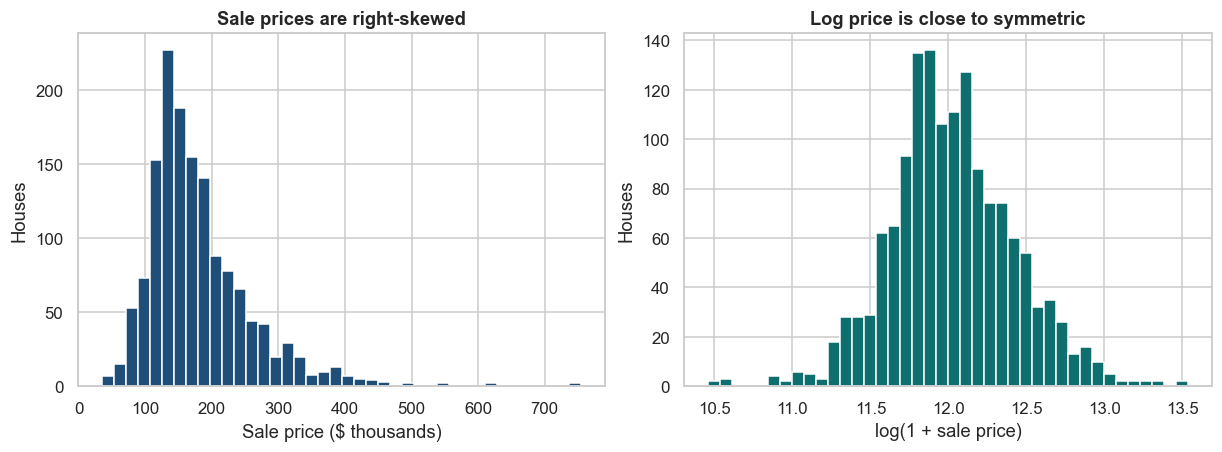

Median price $163,000, mean $180,921, max $755,000.
A few expensive homes pull the mean above the median, so the models train on log price.


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(df["SalePrice"] / 1000, bins=40, color=NAVY, edgecolor="white")
axes[0].set_xlabel("Sale price ($ thousands)")
axes[0].set_ylabel("Houses")
axes[0].set_title("Sale prices are right-skewed")
axes[1].hist(np.log1p(df["SalePrice"]), bins=40, color=TEAL, edgecolor="white")
axes[1].set_xlabel("log(1 + sale price)")
axes[1].set_ylabel("Houses")
axes[1].set_title("Log price is close to symmetric")
finish(fig, "saleprice_distribution.png")

median_price = df["SalePrice"].median()
print(
    f"Median price ${median_price:,.0f}, mean ${df['SalePrice'].mean():,.0f}, "
    f"max ${df['SalePrice'].max():,.0f}."
)
print("A few expensive homes pull the mean above the median, so the models train on log price.")


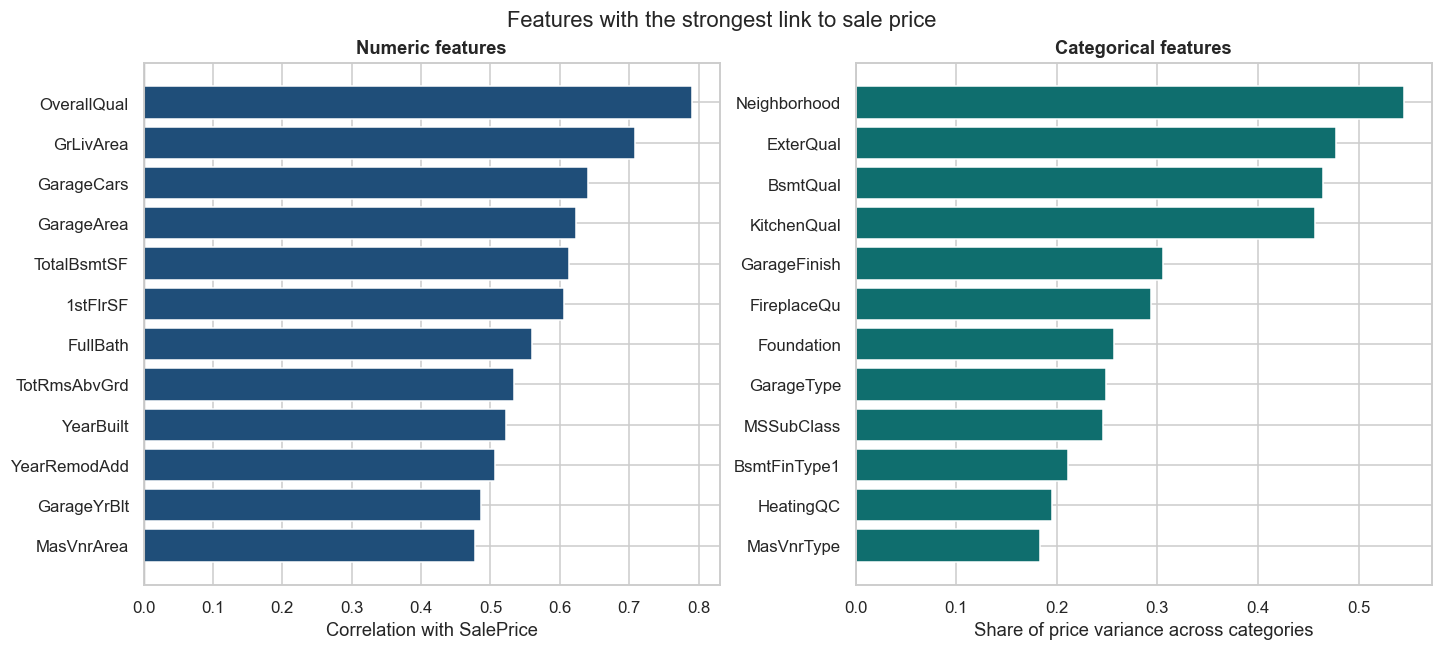

,feature,correlation
0,OverallQual,0.790982
1,GrLivArea,0.708624
2,GarageCars,0.640409
3,GarageArea,0.623431
4,TotalBsmtSF,0.613581
5,1stFlrSF,0.605852
6,FullBath,0.560664
7,TotRmsAbvGrd,0.533723


,feature,variance_share
0,Neighborhood,0.545575
1,ExterQual,0.477388
2,BsmtQual,0.464994
3,KitchenQual,0.456599
4,GarageFinish,0.305874
5,FireplaceQu,0.293961
6,Foundation,0.256368
7,GarageType,0.249204


In [4]:
# MSSubClass is a building-type code, not a magnitude, so it is left out of the correlation ranking.
numeric_features = [
    col
    for col in df.select_dtypes(include="number").columns
    if col not in {"Id", "MSSubClass", "SalePrice"}
]
numeric_corr = (
    df[numeric_features]
    .apply(lambda column: column.corr(df["SalePrice"]))
    .sort_values(key=np.abs, ascending=False)
)


def correlation_ratio(frame: pd.DataFrame, column: str, target: str = "SalePrice") -> float:
    # Share of target variance explained by differences between category means.
    raw = frame[column]
    keys = raw.map(lambda value: "Missing" if pd.isna(value) else value)
    stats = frame.assign(_key=keys).groupby("_key")[target].agg(["mean", "count"])
    overall = frame[target].mean()
    total = ((frame[target] - overall) ** 2).sum()
    between = (stats["count"] * (stats["mean"] - overall) ** 2).sum()
    return float(between / total)


categorical_features = [col for col in df.columns if col not in numeric_features + ["Id", "SalePrice"]]
category_effect = pd.Series(
    {col: correlation_ratio(df, col) for col in categorical_features}
).sort_values(ascending=False)

top_numeric = numeric_corr.head(12).iloc[::-1]
top_category = category_effect.head(12).iloc[::-1]

fig, axes = plt.subplots(1, 2, figsize=(13, 5.8))
num_colors = [NAVY if value > 0 else RED for value in top_numeric]
axes[0].barh(top_numeric.index, top_numeric.values, color=num_colors)
axes[0].axvline(0, color="#666666", linewidth=0.8)
axes[0].set_xlabel("Correlation with SalePrice")
axes[0].set_title("Numeric features")
axes[1].barh(top_category.index, top_category.values, color=TEAL)
axes[1].set_xlabel("Share of price variance across categories")
axes[1].set_title("Categorical features")
fig.suptitle("Features with the strongest link to sale price")
finish(fig, "feature_effects.png")

display(
    pd.DataFrame(
        {
            "feature": numeric_corr.head(8).index,
            "correlation": numeric_corr.head(8).values,
        }
    )
)
display(
    pd.DataFrame(
        {
            "feature": category_effect.head(8).index,
            "variance_share": category_effect.head(8).values,
        }
    )
)


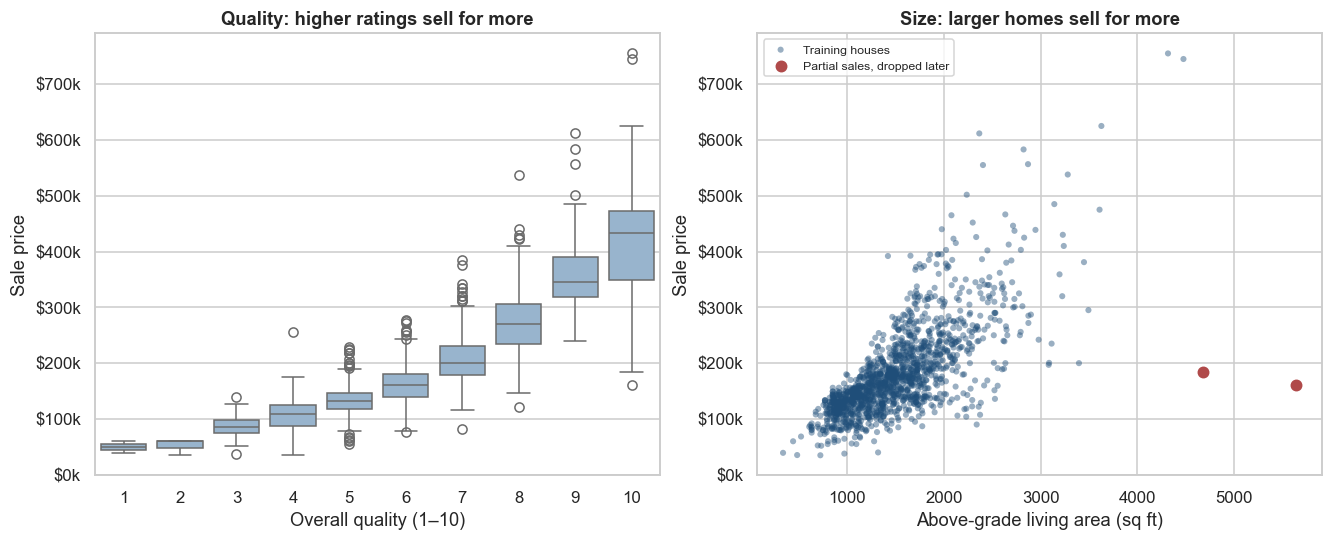

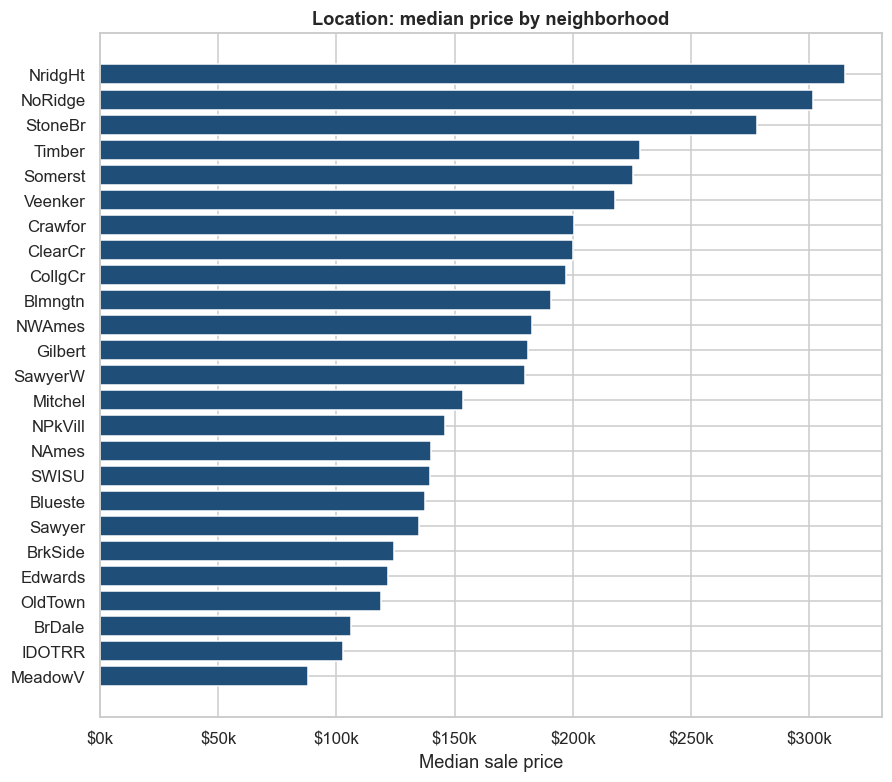

Neighborhood medians range from $88,000 (MeadowV) to $315,000 (NridgHt).


,Id,Neighborhood,OverallQual,GrLivArea,SalePrice
523,524,Edwards,10,4676,184750
1298,1299,Edwards,10,5642,160000


Those two very large, low-priced homes are partial sales. They are removed before training.


In [5]:
partial_sales = (df["GrLivArea"] > 4000) & (df["SalePrice"] < 300_000)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
sns.boxplot(data=df, x="OverallQual", y="SalePrice", color="#8fb4d6", ax=axes[0])
axes[0].set_xlabel("Overall quality (1–10)")
axes[0].set_ylabel("Sale price")
axes[0].set_title("Quality: higher ratings sell for more")
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _pos: f"${v/1000:.0f}k"))

axes[1].scatter(
    df.loc[~partial_sales, "GrLivArea"],
    df.loc[~partial_sales, "SalePrice"],
    s=16,
    alpha=0.45,
    c=NAVY,
    edgecolor="none",
    label="Training houses",
)
axes[1].scatter(
    df.loc[partial_sales, "GrLivArea"],
    df.loc[partial_sales, "SalePrice"],
    s=46,
    c=RED,
    label="Partial sales, dropped later",
)
axes[1].set_xlabel("Above-grade living area (sq ft)")
axes[1].set_ylabel("Sale price")
axes[1].set_title("Size: larger homes sell for more")
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _pos: f"${v/1000:.0f}k"))
axes[1].legend(frameon=True, fontsize=8)
finish(fig, "quality_and_size.png")

neighborhood_price = df.groupby("Neighborhood")["SalePrice"].median().sort_values()
fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(neighborhood_price.index, neighborhood_price.values, color=NAVY)
ax.set_xlabel("Median sale price")
ax.set_title("Location: median price by neighborhood")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _pos: f"${v/1000:.0f}k"))
finish(fig, "neighborhood_prices.png")

print(
    f"Neighborhood medians range from ${neighborhood_price.iloc[0]:,.0f} ({neighborhood_price.index[0]}) "
    f"to ${neighborhood_price.iloc[-1]:,.0f} ({neighborhood_price.index[-1]})."
)
display(df.loc[partial_sales, ["Id", "Neighborhood", "OverallQual", "GrLivArea", "SalePrice"]])
print("Those two very large, low-priced homes are partial sales. They are removed before training.")


## 3. Missing values and categorical encoding

Most blanks are not unknown measurements. In this dataset, `NA` in pool, alley, fence, fireplace, basement, and garage fields means the house does not have that feature. Those columns are filled with `"None"`.

Remaining gaps:

- `GarageYrBlt` is filled with the year the house was built
- other numeric gaps (lot frontage, masonry area) use the **median**
- other categorical gaps use the **most frequent** value

Medians and most-frequent values are learned inside a scikit-learn pipeline, on the training split only. Categories are one-hot encoded. Levels that appear fewer than 5 times are grouped together so rare labels do not create noisy columns. `MSSubClass` and `MoSold` are stored as numbers but are codes, so they are encoded as categories.


column,missing,percent,strategy
PoolQC,1453,99.5%,Fill with None (feature absent)
MiscFeature,1406,96.3%,Fill with None (feature absent)
Alley,1369,93.8%,Fill with None (feature absent)
Fence,1179,80.8%,Fill with None (feature absent)
MasVnrType,872,59.7%,Fill with None (feature absent)
FireplaceQu,690,47.3%,Fill with None (feature absent)
LotFrontage,259,17.7%,"Median, fit on the training split"
GarageYrBlt,81,5.5%,Fill with YearBuilt
GarageType,81,5.5%,Fill with None (feature absent)
GarageFinish,81,5.5%,Fill with None (feature absent)


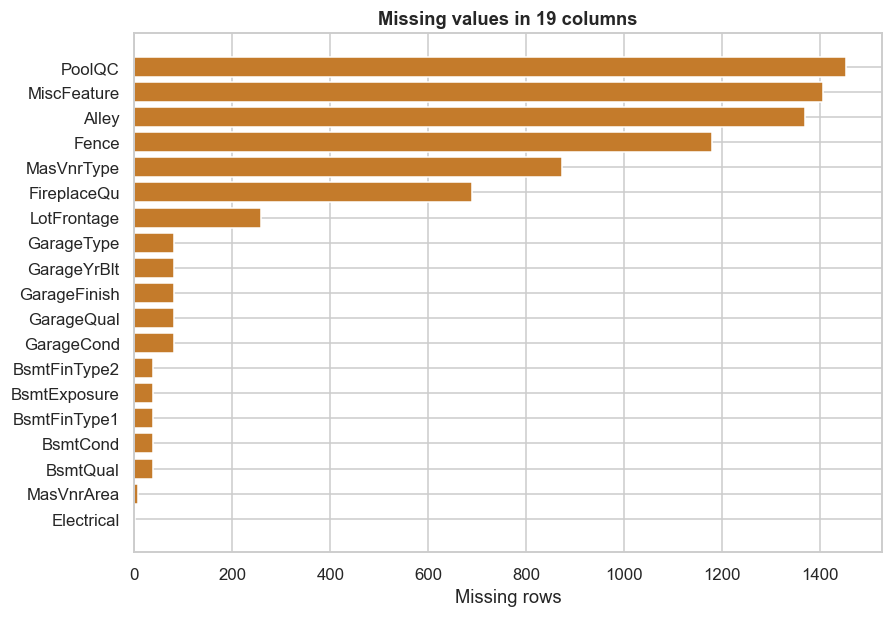

In [6]:
# NA means the feature is absent, not that the value failed to record.
ABSENCE_COLS = [
    "Alley",
    "BsmtQual",
    "BsmtCond",
    "BsmtExposure",
    "BsmtFinType1",
    "BsmtFinType2",
    "FireplaceQu",
    "GarageType",
    "GarageFinish",
    "GarageQual",
    "GarageCond",
    "PoolQC",
    "Fence",
    "MiscFeature",
    "MasVnrType",
]

missing_count = df.isna().sum()
missing_count = missing_count[missing_count > 0].sort_values()

strategies = []
for column, count in missing_count.items():
    if column in ABSENCE_COLS:
        strategy = "Fill with None (feature absent)"
    elif column == "GarageYrBlt":
        strategy = "Fill with YearBuilt"
    elif pd.api.types.is_numeric_dtype(df[column]):
        strategy = "Median, fit on the training split"
    else:
        strategy = "Most frequent value, fit on the training split"
    strategies.append(
        {
            "column": column,
            "missing": int(count),
            "percent": count / len(df),
            "strategy": strategy,
        }
    )
strategy_table = pd.DataFrame(strategies).sort_values("missing", ascending=False)
display(strategy_table.style.format({"percent": "{:.1%}"}).hide(axis="index"))

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(missing_count.index, missing_count.values, color=GOLD)
ax.set_xlabel("Missing rows")
ax.set_title(f"Missing values in {len(missing_count)} columns")
finish(fig, "missing_values.png")


In [7]:
def prepare_features(frame: pd.DataFrame) -> pd.DataFrame:
    prepared = frame.copy()
    prepared["MSSubClass"] = prepared["MSSubClass"].astype(str)
    prepared["MoSold"] = prepared["MoSold"].astype(str)
    prepared["GarageYrBlt"] = prepared["GarageYrBlt"].fillna(prepared["YearBuilt"])
    return prepared


model_df = prepare_features(df.loc[~partial_sales].copy())
y = model_df["SalePrice"]
X = model_df.drop(columns=["SalePrice", "Id"])

absence_cols = [col for col in ABSENCE_COLS if col in X.columns]
other_cats = [
    col for col in X.columns if X[col].dtype == object and col not in absence_cols
]
numeric_cols = [
    col for col in X.columns if col not in absence_cols and col not in other_cats
]
assert set(absence_cols + other_cats + numeric_cols) == set(X.columns)
print(
    f"Modeling {len(model_df):,} houses with {len(numeric_cols)} numeric features, "
    f"{len(absence_cols)} absence categories, and {len(other_cats)} other categories."
)


def make_preprocessor(scale_numeric: bool) -> ColumnTransformer:
    numeric_steps = [("imputer", SimpleImputer(strategy="median"))]
    if scale_numeric:
        numeric_steps.append(("scaler", StandardScaler()))
    encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False, min_frequency=5)
    return ColumnTransformer(
        transformers=[
            ("num", Pipeline(numeric_steps), numeric_cols),
            (
                "abs",
                Pipeline(
                    [
                        ("imputer", SimpleImputer(strategy="constant", fill_value="None")),
                        ("encoder", encoder),
                    ]
                ),
                absence_cols,
            ),
            (
                "cat",
                Pipeline(
                    [
                        ("imputer", SimpleImputer(strategy="most_frequent")),
                        (
                            "encoder",
                            OneHotEncoder(
                                handle_unknown="ignore",
                                sparse_output=False,
                                min_frequency=5,
                            ),
                        ),
                    ]
                ),
                other_cats,
            ),
        ]
    )


Modeling 1,458 houses with 34 numeric features, 15 absence categories, and 30 other categories.


## 4. Train Linear Regression, Random Forest, and Gradient Boosting

The split is 80% train and 20% holdout (`random_state=42`). Models fit `log(1 + SalePrice)` because the raw price is skewed. Predictions are converted back with `expm1` before RMSE and R², so both metrics are in dollars of sale price. Log RMSE is also reported because that is the scale Kaggle uses.

Linear Regression gets standardized numeric inputs. The tree models do not need that scaling. Settings are fixed in advance: this is a comparison of model families, not a tuned contest.

Two groups of columns repeat each other exactly: `GrLivArea` is `1stFlrSF + 2ndFlrSF + LowQualFinSF`, and `TotalBsmtSF` is the sum of the basement-area parts. One-hot columns for a single category also add up to 1. Ordinary least squares turns those copies into enormous cancelling coefficients, which then overflow on holdout houses. The linear pipeline drops encoded columns that add almost no new information. Random Forest and Gradient Boosting keep the full matrix.


In [8]:
class DropCollinear(BaseEstimator, TransformerMixin):
    # QR with pivoting. Columns that repeat information already in the matrix are removed.
    def __init__(self, tol: float = 1e-2):
        self.tol = tol

    def fit(self, X, y=None):
        matrix = np.asarray(X, dtype=float)
        _q, r, pivots = qr(matrix, mode="economic", pivoting=True)
        diagonal = np.abs(np.diag(r))
        if len(diagonal) == 0:
            rank = 0
        else:
            rank = int(np.sum(diagonal > self.tol * diagonal[0]))
        self.keep_ = np.sort(pivots[:rank])
        self.n_features_in_ = matrix.shape[1]
        return self

    def transform(self, X):
        return np.asarray(X, dtype=float)[:, self.keep_]


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
y_train_log = np.log1p(y_train)

models = {
    "Linear Regression": Pipeline(
        [
            ("prep", make_preprocessor(scale_numeric=True)),
            ("drop_collinear", DropCollinear()),
            ("model", LinearRegression()),
        ]
    ),
    "Random Forest": Pipeline(
        [
            ("prep", make_preprocessor(scale_numeric=False)),
            (
                "model",
                RandomForestRegressor(
                    n_estimators=300,
                    min_samples_leaf=2,
                    random_state=42,
                    n_jobs=-1,
                ),
            ),
        ]
    ),
    "Gradient Boosting": Pipeline(
        [
            ("prep", make_preprocessor(scale_numeric=False)),
            (
                "model",
                GradientBoostingRegressor(
                    n_estimators=400,
                    learning_rate=0.05,
                    max_depth=3,
                    subsample=0.8,
                    random_state=42,
                ),
            ),
        ]
    ),
}

fitted = {}
predictions = {}
rows = []
for name, model in models.items():
    model.fit(X_train, y_train_log)
    pred_log = model.predict(X_test)
    if not np.isfinite(pred_log).all():
        raise ValueError(f"{name} produced non-finite predictions")
    pred = np.expm1(pred_log)
    rmse = root_mean_squared_error(y_test, pred)
    r2 = r2_score(y_test, pred)
    log_rmse = root_mean_squared_error(np.log1p(y_test), pred_log)
    fitted[name] = model
    predictions[name] = pred
    rows.append({"model": name, "RMSE": rmse, "R2": r2, "log_RMSE": log_rmse})
    print(f"{name:20}  RMSE ${rmse:,.0f}   R² {r2:.3f}   log RMSE {log_rmse:.4f}")

metrics = pd.DataFrame(rows)
linear_drop = fitted["Linear Regression"].named_steps["drop_collinear"]
print(
    f"Linear Regression kept {len(linear_drop.keep_)} of "
    f"{linear_drop.n_features_in_} encoded columns."
)
print(f"Holdout houses: {len(y_test):,}   Training houses: {len(y_train):,}")


Linear Regression     RMSE $21,786   R² 0.914   log RMSE 0.1347


Random Forest         RMSE $23,974   R² 0.896   log RMSE 0.1440


Gradient Boosting     RMSE $19,434   R² 0.932   log RMSE 0.1142
Linear Regression kept 237 of 293 encoded columns.
Holdout houses: 292   Training houses: 1,166


## 5. Compare RMSE and R²

RMSE is the typical size of the dollar error (larger errors count more). R² is the share of holdout price variation the model explains. Lower RMSE is better. Higher R² is better.


model,RMSE,R2,log_RMSE
Linear Regression,"$21,786",0.914,0.1347
Random Forest,"$23,974",0.896,0.1440
Gradient Boosting,"$19,434",0.932,0.1142


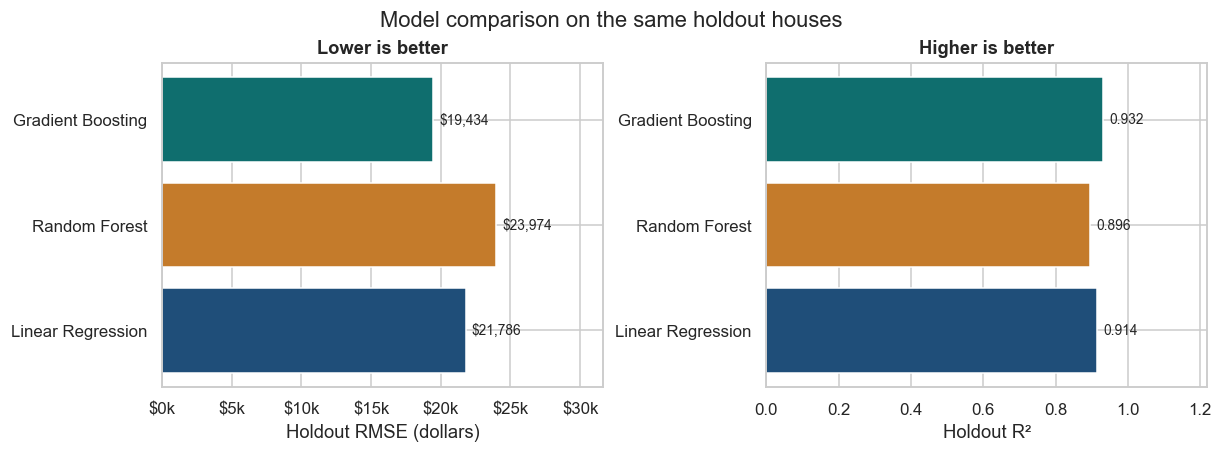

In [9]:
display(
    metrics.style.format(
        {"RMSE": "${:,.0f}", "R2": "{:.3f}", "log_RMSE": "{:.4f}"}
    ).hide(axis="index")
)
metrics.to_csv(OUT / "metrics.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
names = metrics["model"].tolist()
y_pos = np.arange(len(names))
bar_colors = [MODEL_COLORS[name] for name in names]

rmse_bars = axes[0].barh(y_pos, metrics["RMSE"], color=bar_colors)
axes[0].set_yticks(y_pos, names)
axes[0].set_xlabel("Holdout RMSE (dollars)")
axes[0].set_title("Lower is better")
axes[0].xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _pos: f"${v/1000:.0f}k"))
axes[0].bar_label(rmse_bars, labels=[f"${v:,.0f}" for v in metrics["RMSE"]], padding=4, fontsize=9)
axes[0].set_xlim(0, metrics["RMSE"].max() * 1.32)

r2_bars = axes[1].barh(y_pos, metrics["R2"], color=bar_colors)
axes[1].set_yticks(y_pos, names)
axes[1].set_xlabel("Holdout R²")
axes[1].set_title("Higher is better")
axes[1].bar_label(r2_bars, labels=[f"{v:.3f}" for v in metrics["R2"]], padding=4, fontsize=9)
axes[1].set_xlim(0, 1.22)

fig.suptitle("Model comparison on the same holdout houses")
finish(fig, "model_comparison.png")


## 6. Actual vs. predicted prices

Each point is one holdout house. Points on the gray line were predicted exactly. Points above the line are overpriced by the model; points below it are underpriced.


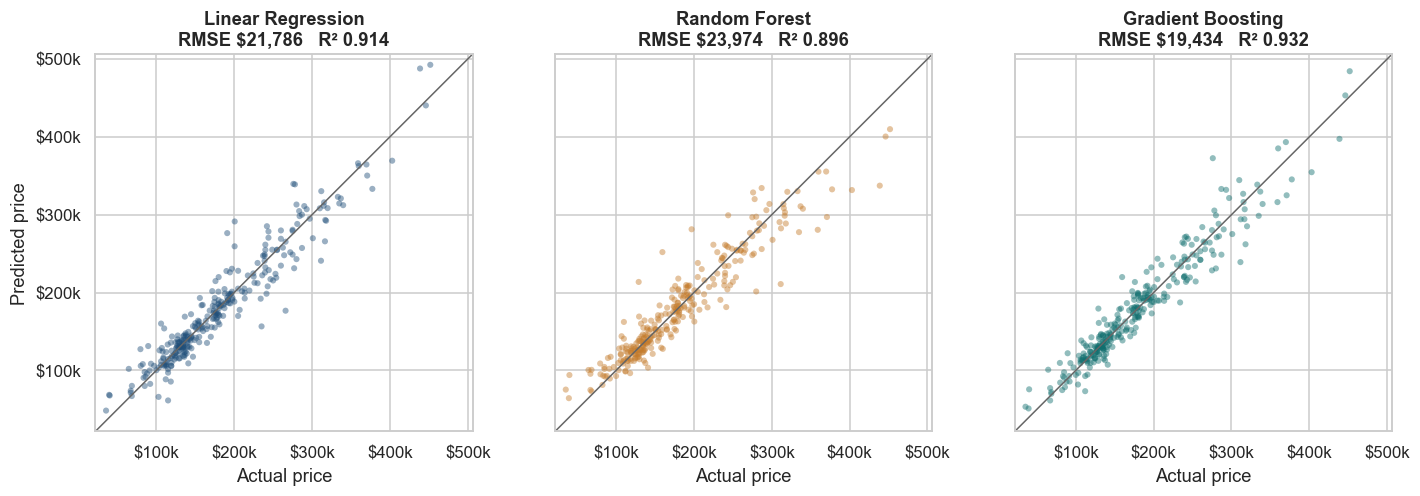

In [10]:
price_formatter = plt.FuncFormatter(lambda v, _pos: f"${v/1000:.0f}k")
all_preds = np.concatenate([predictions[name] for name in names])
low = min(y_test.min(), all_preds.min())
high = max(y_test.max(), all_preds.max())
padding = (high - low) * 0.03
limits = (low - padding, high + padding)

fig, axes = plt.subplots(1, 3, figsize=(13, 4.4), sharex=True, sharey=True)
for ax, name in zip(axes, names):
    pred = predictions[name]
    row = metrics.loc[metrics["model"] == name].iloc[0]
    ax.scatter(y_test, pred, s=16, alpha=0.45, c=MODEL_COLORS[name], edgecolor="none")
    ax.plot(limits, limits, color="#666666", linewidth=1)
    ax.set_xlim(limits)
    ax.set_ylim(limits)
    ax.set_aspect("equal", adjustable="box")
    ax.set_title(f"{name}\nRMSE ${row['RMSE']:,.0f}   R² {row['R2']:.3f}")
    ax.set_xlabel("Actual price")
    ax.xaxis.set_major_formatter(price_formatter)
    ax.yaxis.set_major_formatter(price_formatter)
axes[0].set_ylabel("Predicted price")
finish(fig, "actual_vs_predicted.png")


## 7. Which features the best tree model uses

One-hot encoding splits each category into many columns. Importances are added back up to the original feature so the ranking can be compared with the exploration charts. This is association inside the model, not a claim that renovating one feature would raise the price by a set amount.


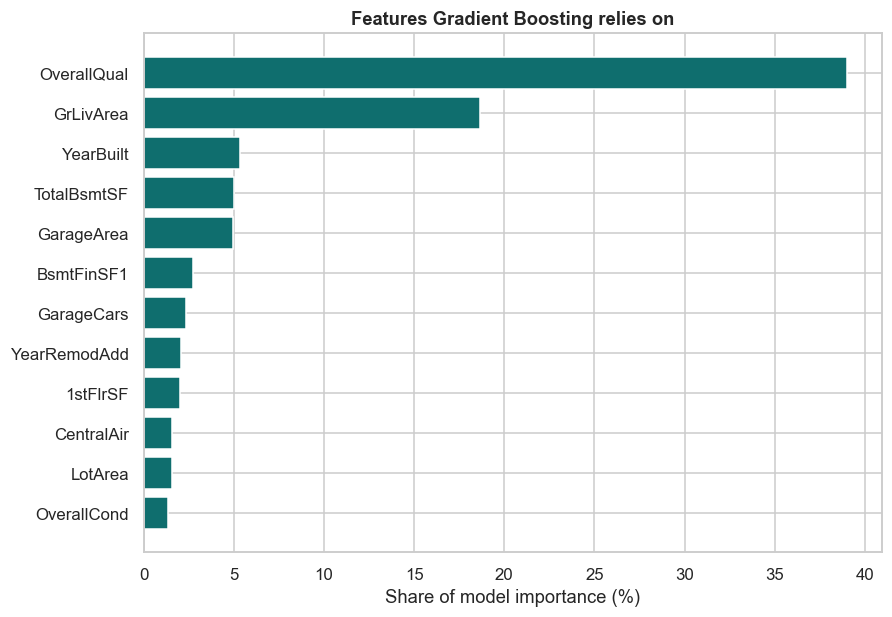

,importance_%
OverallQual,39.0
GrLivArea,18.6
YearBuilt,5.3
TotalBsmtSF,5.0
GarageArea,5.0
BsmtFinSF1,2.7
GarageCars,2.4
YearRemodAdd,2.1
1stFlrSF,2.0
CentralAir,1.6


In [11]:
def group_importances(feature_names, importances, categorical_names) -> pd.Series:
    categories = sorted(categorical_names, key=len, reverse=True)
    totals: dict[str, float] = {}
    for name, value in zip(feature_names, importances):
        prefix, _, rest = name.partition("__")
        if prefix == "num":
            key = rest
        else:
            key = rest
            for category in categories:
                if rest == category or rest.startswith(category + "_"):
                    key = category
                    break
        totals[key] = totals.get(key, 0.0) + float(value)
    return pd.Series(totals).sort_values(ascending=False)


best_name = metrics.sort_values(["RMSE", "model"]).iloc[0]["model"]
importance_model = best_name if best_name != "Linear Regression" else "Gradient Boosting"
prep = fitted[importance_model].named_steps["prep"]
estimator = fitted[importance_model].named_steps["model"]
grouped_importance = group_importances(
    prep.get_feature_names_out(),
    estimator.feature_importances_,
    absence_cols + other_cats,
)

top_importance = grouped_importance.head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(top_importance.index, top_importance.values * 100, color=MODEL_COLORS[importance_model])
ax.set_xlabel("Share of model importance (%)")
ax.set_title(f"Features {importance_model} relies on")
finish(fig, "feature_importance.png")
display(grouped_importance.head(12).mul(100).round(1).to_frame("importance_%"))


## 8. Results


In [12]:
best = metrics.sort_values(["RMSE", "model"]).iloc[0]
baseline = metrics.loc[metrics["model"] == "Linear Regression"].iloc[0]
top_num = numeric_corr.head(3)
top_cat = category_effect.head(3)
top_used = grouped_importance.head(3)
rmse_vs_median = best["RMSE"] / df["SalePrice"].median()

parts = [
    (
        f"The best holdout model is **{best['model']}**, with RMSE "
        f"**${best['RMSE']:,.0f}** and R² **{best['R2']:.3f}**. "
        f"That error is about **{rmse_vs_median:.0%}** of the median sale price "
        f"(${df['SalePrice'].median():,.0f}). Log RMSE is {best['log_RMSE']:.4f}."
    ),
    (
        f"Linear Regression is the baseline at RMSE **${baseline['RMSE']:,.0f}** "
        f"and R² **{baseline['R2']:.3f}**."
        + (
            " It has the lowest error on this split."
            if best["model"] == "Linear Regression"
            else (
                f" {best['model']} reduces that error by "
                f"**${baseline['RMSE'] - best['RMSE']:,.0f}**."
            )
        )
    ),
    (
        "Price moves most with **quality, size, and location**. The strongest numeric "
        f"links are {', '.join(f'{name} ({value:+.2f})' for name, value in top_num.items())}. "
        "The categorical features that separate price levels are "
        f"{', '.join(f'{name} ({value:.0%} of variance)' for name, value in top_cat.items())}."
    ),
    (
        f"{importance_model} puts the most weight on "
        f"{', '.join(f'{name} ({value:.0%})' for name, value in top_used.items())}, "
        "which matches the exploration."
    ),
    (
        "Missing values were filled rather than dropped. Pool, alley, fence, fireplace, "
        "basement, and garage blanks were coded as `None` because they mean the feature "
        "is absent. Two partial sales with living area above 4,000 sq ft were removed "
        "before the split."
    ),
]
display(Markdown("\n\n".join(parts)))


The best holdout model is **Gradient Boosting**, with RMSE **$19,434** and R² **0.932**. That error is about **12%** of the median sale price ($163,000). Log RMSE is 0.1142.

Linear Regression is the baseline at RMSE **$21,786** and R² **0.914**. Gradient Boosting reduces that error by **$2,351**.

Price moves most with **quality, size, and location**. The strongest numeric links are OverallQual (+0.79), GrLivArea (+0.71), GarageCars (+0.64). The categorical features that separate price levels are Neighborhood (55% of variance), ExterQual (48% of variance), BsmtQual (46% of variance).

Gradient Boosting puts the most weight on OverallQual (39%), GrLivArea (19%), YearBuilt (5%), which matches the exploration.

Missing values were filled rather than dropped. Pool, alley, fence, fireplace, basement, and garage blanks were coded as `None` because they mean the feature is absent. Two partial sales with living area above 4,000 sq ft were removed before the split.